# Análise de Risco de Crédito: Give Me Some Credit (Kaggle)

Estudo da base  **[Give Me Some Credit](https://www.kaggle.com/competitions/GiveMeSomeCredit)**

### Objetivo
Prever a probabilidade de um cliente entrar em situação de inadimplência grave (atraso superior a 90 dias) nos próximos 2 anos inadimplente_2anos.


### 1. Imports

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

### 2. Data Load
O código abaixo verifica se o arquivo local existe em `dados/give_me_some_credit.csv`. Se não encontrar, faz a leitura direta via URL pública do GitHub.

In [3]:
caminho_local = os.path.join('dados', 'give_me_some_credit.csv')
url_github = 'https://raw.githubusercontent.com/ricalgarve/analise-dados/main/credito_bureau_eua/dados/give_me_some_credit.csv'

if os.path.exists(caminho_local):
    print(f'Carregando base a partir do disco local: {caminho_local}')
    df = pd.read_csv(caminho_local)
else:
    print(f'Arquivo local não encontrado. Baixando direto do GitHub...')
    df = pd.read_csv(url_github)

print(f'Tamanho do dataset: {df.shape[0]:,} linhas e {df.shape[1]} colunas')
df.head()

Carregando base a partir do disco local: dados\give_me_some_credit.csv
Tamanho do dataset: 150,000 linhas e 11 colunas


,inadimplente_2anos,utilizacao_credito_rotativo,idade,atrasos_30_59_dias,indice_endividamento,renda_mensal,qtd_linhas_credito_abertas,atrasos_acima_90_dias,qtd_financiamentos_imoveis,atrasos_60_89_dias,qtd_dependentes
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


### 3. Inspeção Geral e Tipos de Dados

In [4]:
# Informações de tipos, contagem de preenchidos e uso de memória
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   inadimplente_2anos           150000 non-null  int64  
 1   utilizacao_credito_rotativo  150000 non-null  float64
 2   idade                        150000 non-null  int64  
 3   atrasos_30_59_dias           150000 non-null  int64  
 4   indice_endividamento         150000 non-null  float64
 5   renda_mensal                 120269 non-null  float64
 6   qtd_linhas_credito_abertas   150000 non-null  int64  
 7   atrasos_acima_90_dias        150000 non-null  int64  
 8   qtd_financiamentos_imoveis   150000 non-null  int64  
 9   atrasos_60_89_dias           150000 non-null  int64  
 10  qtd_dependentes              146076 non-null  float64
dtypes: float64(4), int64(7)
memory usage: 12.6 MB


In [5]:
# Resumo estatístico inicial das variáveis numéricas
df.describe().round(2)

,inadimplente_2anos,utilizacao_credito_rotativo,idade,atrasos_30_59_dias,indice_endividamento,renda_mensal,qtd_linhas_credito_abertas,atrasos_acima_90_dias,qtd_financiamentos_imoveis,atrasos_60_89_dias,qtd_dependentes
count,150000.00,150000.00,150000.00,150000.00,150000.00,120269.00,150000.00,150000.00,150000.00,150000.00,146076.00
mean,0.07,6.05,52.30,0.42,353.01,6670.22,8.45,0.27,1.02,0.24,0.76
std,0.25,249.76,14.77,4.19,2037.82,14384.67,5.15,4.17,1.13,4.16,1.12
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.03,41.00,0.00,0.18,3400.00,5.00,0.00,0.00,0.00,0.00
50%,0.00,0.15,52.00,0.00,0.37,5400.00,8.00,0.00,1.00,0.00,0.00
75%,0.00,0.56,63.00,0.00,0.87,8249.00,11.00,0.00,2.00,0.00,1.00
max,1.00,50708.00,109.00,98.00,329664.00,3008750.00,58.00,98.00,54.00,98.00,20.00


### 4. Diagnóstico de Dados Ausentes (Missing Values)

In [ ]:
nulos = df.isnull().sum()
percentual_nulos = (nulos / len(df)) * 100

tabela_nulos = pd.DataFrame({
    'Quantidade Nulos': nulos,
    'Percentual (%)': percentual_nulos
})

#tabela_nulos.head()

tabela_nulos[tabela_nulos['Quantidade Nulos'] > 0].round(2)

,Quantidade Nulos,Percentual (%)
inadimplente_2anos,0,0.0
utilizacao_credito_rotativo,0,0.0
idade,0,0.0
atrasos_30_59_dias,0,0.0
indice_endividamento,0,0.0


### 5. Análise da Variável Alvo inadimplente_2anos

Frequência absoluta:
inadimplente_2anos
0    139974
1     10026
Name: count, dtype: int64

Frequência relativa (%):
inadimplente_2anos
0    93.32
1     6.68
Name: proportion, dtype: float64


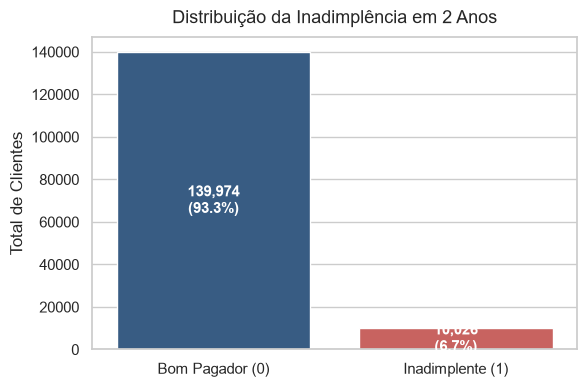

In [8]:
contagem_alvo = df['inadimplente_2anos'].value_counts()
proporcao_alvo = df['inadimplente_2anos'].value_counts(normalize=True) * 100

print('Frequência absoluta:')
print(contagem_alvo)
print('\nFrequência relativa (%):')
print(proporcao_alvo.round(2))

# Gráfico de distribuição do target (sintaxe atualizada)
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(
    data=df, 
    x='inadimplente_2anos', 
    hue='inadimplente_2anos', 
    palette=['#2b5c8f', '#d9534f'], 
    legend=False, 
    ax=ax
)

ax.set_title('Distribuição da Inadimplência em 2 Anos', fontsize=13, pad=10)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Bom Pagador (0)', 'Inadimplente (1)'])
ax.set_xlabel('')
ax.set_ylabel('Total de Clientes')

# Rótulos nas barras
for p in ax.patches:
    altura = int(p.get_height())
    ax.annotate(
        f'{altura:,}\n({altura/len(df)*100:.1f}%)',
        (p.get_x() + p.get_width() / 2., altura / 2),
        ha='center', va='center', color='white', fontweight='bold'
    )

plt.tight_layout()
plt.show()

### 6. Filtrando clientes com histórico de atraso nas 3 faixas simultaneamente

Total de clientes com atrasos nas 3 faixas: 1,974 (1.32% da base)
Taxa de inadimplência em 2 anos (alvo) no grupo: 57.4%
Taxa de inadimplência na base geral: 6.7%
Aumento de risco relativo: 8.6x mais chances de default futuro


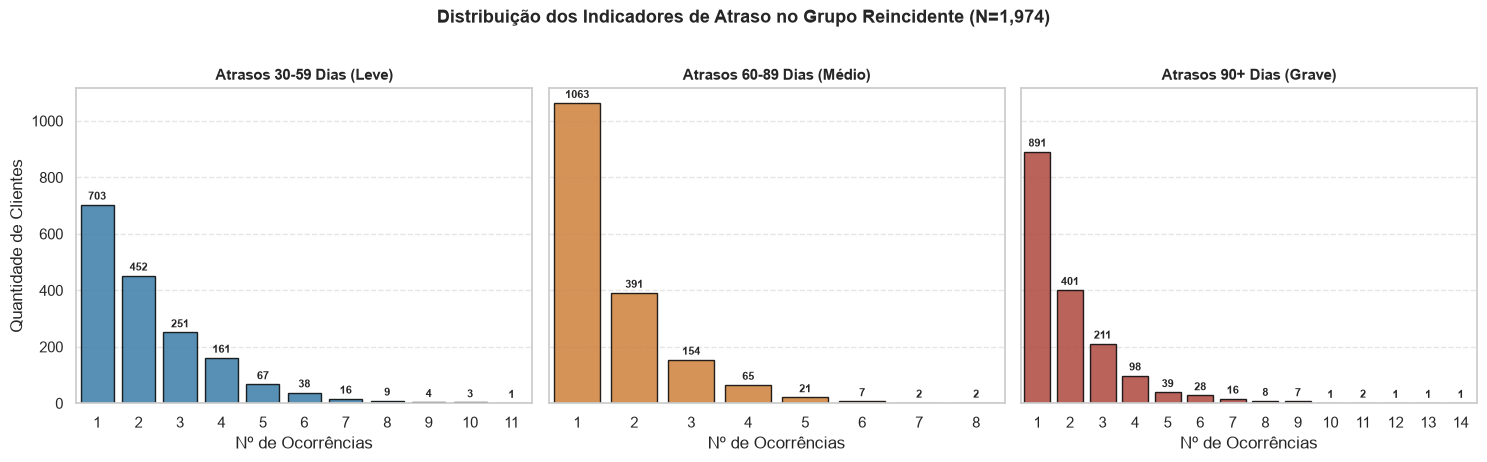

,inadimplente_2anos,utilizacao_credito_rotativo,idade,atrasos_30_59_dias,indice_endividamento,renda_mensal,qtd_linhas_credito_abertas,atrasos_acima_90_dias,qtd_financiamentos_imoveis,atrasos_60_89_dias,qtd_dependentes
13,1,0.964673,40,3,0.382965,13700.0,9,3,1,1,2.0
191,0,1.095083,53,5,0.536704,3500.0,7,1,1,2,0.0
319,0,1.002647,38,2,0.472543,3550.0,8,1,0,1,4.0
352,0,0.507973,69,2,0.193935,3000.0,10,2,0,2,0.0
354,1,0.953344,48,2,2073.000000,NaN,5,1,2,2,0.0


In [7]:
# Filtrando clientes com histórico de atraso nas 3 faixas simultaneamente
inadimplentes = df[
    (df['atrasos_30_59_dias'] > 0) &
    (df['atrasos_60_89_dias'] > 0) &
    (df['atrasos_acima_90_dias'] > 0)
].copy()

taxa_inadimp_grupo = inadimplentes['inadimplente_2anos'].mean() * 100
taxa_inadimp_geral = df['inadimplente_2anos'].mean() * 100
razao_risco = taxa_inadimp_grupo / taxa_inadimp_geral

print(f"Total de clientes com atrasos nas 3 faixas: {len(inadimplentes):,} ({len(inadimplentes)/len(df)*100:.2f}% da base)")
print(f"Taxa de inadimplência em 2 anos (alvo) no grupo: {taxa_inadimp_grupo:.1f}%")
print(f"Taxa de inadimplência na base geral: {taxa_inadimp_geral:.1f}%")
print(f"Aumento de risco relativo: {razao_risco:.1f}x mais chances de default futuro")

# Gráfico de distribuição dos 3 indicadores de atraso
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
indicadores = [
    ('atrasos_30_59_dias', 'Atrasos 30-59 Dias (Leve)', '#2980b9'),
    ('atrasos_60_89_dias', 'Atrasos 60-89 Dias (Médio)', '#e67e22'),
    ('atrasos_acima_90_dias', 'Atrasos 90+ Dias (Grave)', '#c0392b')
]

for ax, (col, titulo, cor) in zip(axes, indicadores):
    dados_plot = inadimplentes[inadimplentes[col] < 90][col]
    sns.countplot(x=dados_plot, ax=ax, color=cor, edgecolor='black', alpha=0.85)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_xlabel('Nº de Ocorrências')
    ax.set_ylabel('Quantidade de Clientes' if ax == axes[0] else '')
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    for p in ax.patches:
        h = int(p.get_height())
        if h > 0:
            ax.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                        ha='center', va='bottom', fontsize=8, fontweight='bold',
                        xytext=(0, 2), textcoords='offset points')

plt.suptitle(f'Distribuição dos Indicadores de Atraso no Grupo Reincidente (N={len(inadimplentes):,})',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

inadimplentes.head()

### Endividamento por idate

O Grafico a direita mostra melhor a taxa em relação aos totais, pois hoje a base conta com mais idosos que jovens.

Total menos de 30: 8821
Total mais de 60: 45060


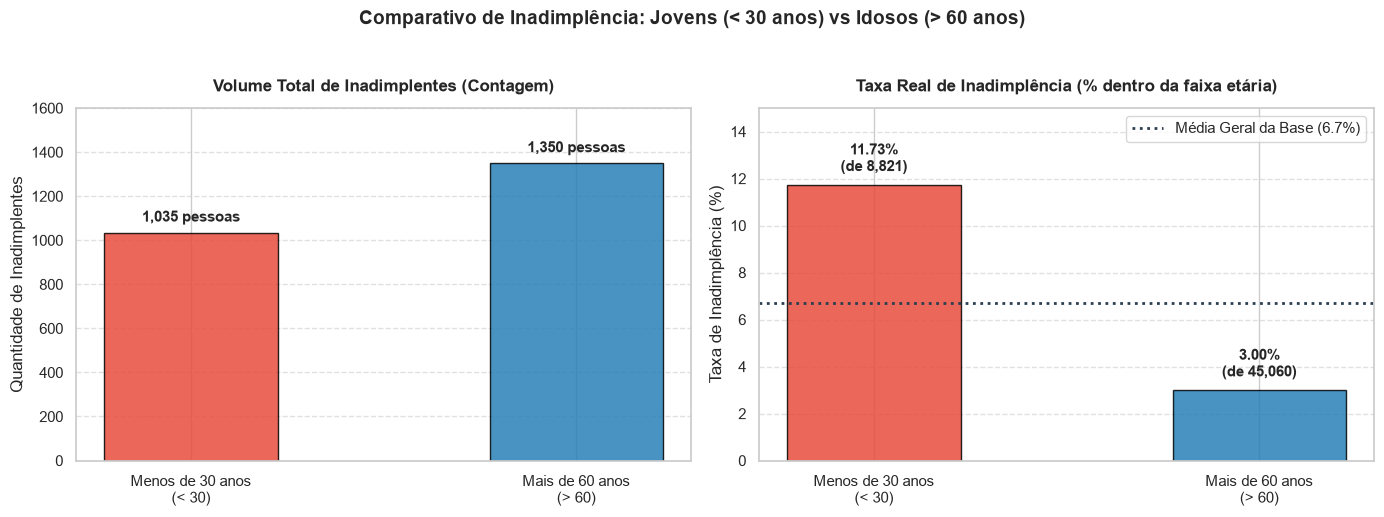

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração do estilo visual
sns.set_theme(style='whitegrid')

# 1. Filtros dos grupos solicitados
clientesMenos30 = df[(df['idade'] < 30) & (df['inadimplente_2anos'] == 1)].copy()
clientesMais60 = df[(df['idade'] > 60) & (df['inadimplente_2anos'] == 1)].copy()

# 2. Totais das faixas etárias para calcular o percentual real (%)
total_menos_30 = len(df[df['idade'] < 30])
total_mais_60 = len(df[df['idade'] > 60])

print(f'Total menos de 30: {total_menos_30}')
print(f'Total mais de 60: {total_mais_60}')

taxa_menos_30 = (len(clientesMenos30) / total_menos_30) * 100
taxa_mais_60 = (len(clientesMais60) / total_mais_60) * 100
media_geral = df['inadimplente_2anos'].mean() * 100

# 3. Construção do gráfico com 2 painéis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
grupos = ['Menos de 30 anos\n(< 30)', 'Mais de 60 anos\n(> 60)']
cores = ['#e74c3c', '#2980b9']

# Painel 1: Volume Absoluto de Inadimplentes
qtd_inadimp = [len(clientesMenos30), len(clientesMais60)]
bars1 = axes[0].bar(grupos, qtd_inadimp, color=cores, width=0.45, edgecolor='black', alpha=0.85)
axes[0].set_title('Volume Total de Inadimplentes (Contagem)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel('Quantidade de Inadimplentes')
axes[0].set_ylim(0, 1600)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars1:
    h = bar.get_height()
    axes[0].annotate(f'{h:,} pessoas', (bar.get_x() + bar.get_width() / 2., h + 35),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

# Painel 2: Taxa Real de Inadimplência (% dentro do grupo)
taxas = [taxa_menos_30, taxa_mais_60]
bars2 = axes[1].bar(grupos, taxas, color=cores, width=0.45, edgecolor='black', alpha=0.85)
axes[1].set_title('Taxa Real de Inadimplência (% dentro da faixa etária)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_ylabel('Taxa de Inadimplência (%)')
axes[1].set_ylim(0, 15)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

# Linha de referência da média geral
axes[1].axhline(media_geral, color='#2c3e50', linestyle=':', linewidth=2, label=f'Média Geral da Base ({media_geral:.1f}%)')
axes[1].legend(loc='upper right', frameon=True)

for bar, total_grp in zip(bars2, [total_menos_30, total_mais_60]):
    h = bar.get_height()
    axes[1].annotate(f'{h:.2f}%\n(de {total_grp:,})', (bar.get_x() + bar.get_width() / 2., h + 0.4),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.suptitle('Comparativo de Inadimplência: Jovens (< 30 anos) vs Idosos (> 60 anos)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

Acima é possível verificar no gráfico a direita, baseado nas taxas que de todos os jovens, até mesmo os adimplentes, esse é o grupo com maior taxa de inadimplência.  11,73%, ou seja, a cada 100 jovens  12 não consegue pagar. Já para idosos a cada 100 apenas 3 não conseguem pagar.

### Análise para verificar relação de clientes com dependentes com inadimplência

,faixa_dependentes,total,inadimplentes,taxa_inadimplencia
0,0,86902,5095,5.862926
1,1,26316,1935,7.352941
2,2,19522,1584,8.113923
3,3,9483,837,8.826321
4,4,2862,297,10.377358
5,5+,991,99,9.989909


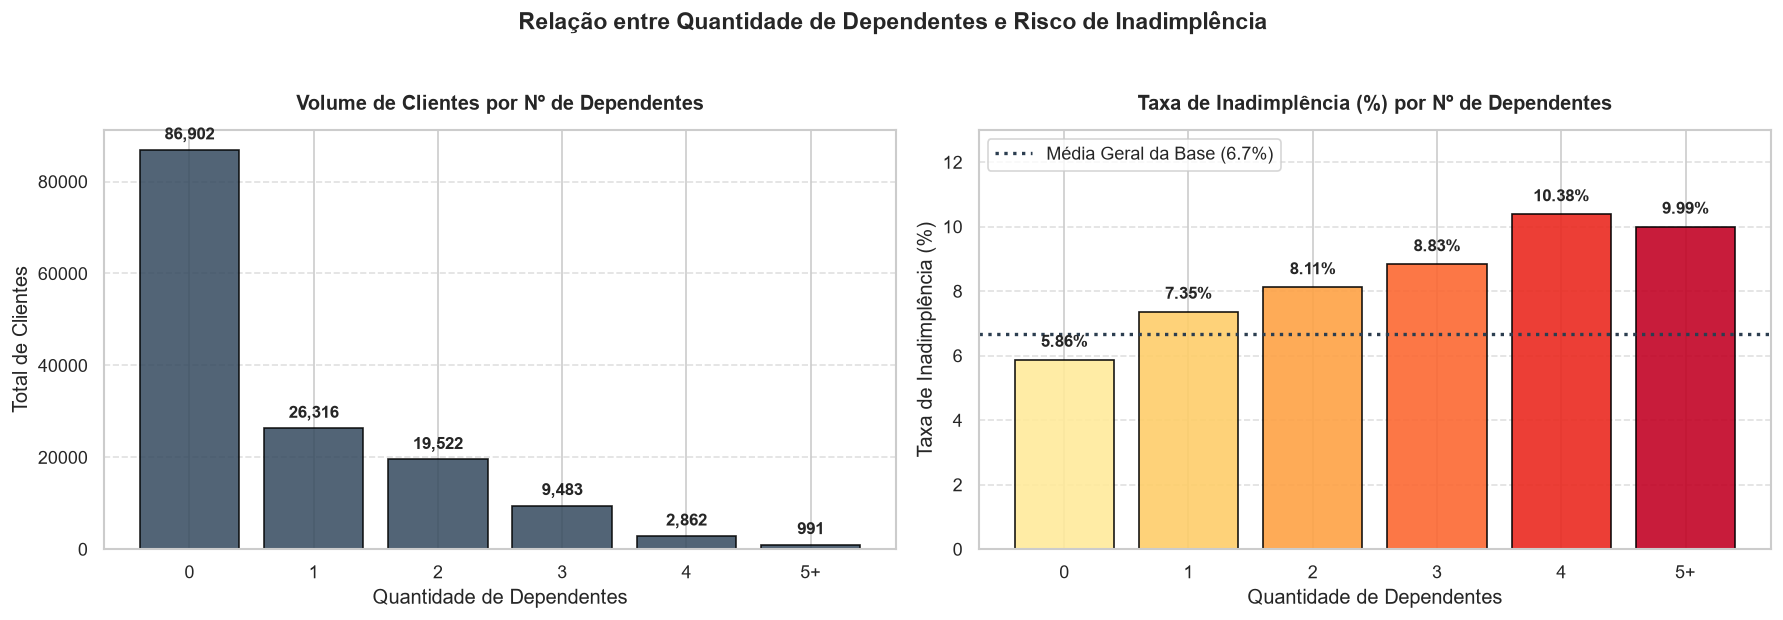

In [15]:

# Configuração do estilo visual
sns.set_theme(style='whitegrid')

# 1. Agrupamento por dependentes (agrupando 5 ou mais para evitar cauda longa)
df_dep = df.dropna(subset=['qtd_dependentes']).copy()
df_dep['faixa_dependentes'] = df_dep['qtd_dependentes'].apply(lambda x: '5+' if x >= 5 else str(int(x)))

# 2. Tabela resumo com contagem, inadimplentes e taxa (%)
resumo_dep = df_dep.groupby('faixa_dependentes').agg(
    total=('inadimplente_2anos', 'count'),
    inadimplentes=('inadimplente_2anos', 'sum'),
    taxa_inadimplencia=('inadimplente_2anos', lambda x: x.mean() * 100)
).loc[['0', '1', '2', '3', '4', '5+']].reset_index()

# Exibe a tabela no notebook
display(resumo_dep)

# 3. Construção dos gráficos comparativos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
media_geral = df['inadimplente_2anos'].mean() * 100

# Gráfico 1: Volume de clientes por quantidade de dependentes
bars1 = axes[0].bar(resumo_dep['faixa_dependentes'], resumo_dep['total'], color='#34495e', edgecolor='black', alpha=0.85)
axes[0].set_title('Volume de Clientes por Nº de Dependentes', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Quantidade de Dependentes')
axes[0].set_ylabel('Total de Clientes')
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars1:
    h = bar.get_height()
    axes[0].annotate(f'{h:,}', (bar.get_x() + bar.get_width() / 2., h + 1500),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# Gráfico 2: Taxa real de inadimplência (%) por quantidade de dependentes
cores = sns.color_palette('YlOrRd', len(resumo_dep))
bars2 = axes[1].bar(resumo_dep['faixa_dependentes'], resumo_dep['taxa_inadimplencia'], color=cores, edgecolor='black', alpha=0.9)
axes[1].set_title('Taxa de Inadimplência (%) por Nº de Dependentes', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Quantidade de Dependentes')
axes[1].set_ylabel('Taxa de Inadimplência (%)')
axes[1].set_ylim(0, 13)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

# Linha de referência da média geral
axes[1].axhline(media_geral, color='#2c3e50', linestyle=':', linewidth=2, label=f'Média Geral da Base ({media_geral:.1f}%)')
axes[1].legend(loc='upper left', frameon=True)

for bar in bars2:
    h = bar.get_height()
    axes[1].annotate(f'{h:.2f}%', (bar.get_x() + bar.get_width() / 2., h + 0.3),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Relação entre Quantidade de Dependentes e Risco de Inadimplência', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Conclusão sobre Dependentes:**
- Clientes **sem dependentes** têm taxa de inadimplência de **5,86%** (abaixo da média geral de 6,68%).
- Conforme o número de filhos/dependentes aumenta, a taxa de inadimplência sobe quase em linha reta: chega a **8,11%** com 2 filhos e atinge **10,38%** em famílias com 4 dependentes.
- Isso reflete o orçamento familiar mais apertado e a maior vulnerabilidade a despesas emergenciais imprevistas.

### 8. Análise da Utilização de Crédito Rotativo (`utilizacao_credito_rotativo`)

A taxa de utilização mede o percentual do limite de crédito que o cliente está usando (ex: faturas de cartão de crédito e cheque especial em aberto divididos pelo limite total concedido).
- Valores **até 30%** são considerados pelo mercado como saudáveis.
- Valores **acima de 100%** indicam cheque especial estourado ou compras acima do limite de crédito permitido.

,faixa_rotativo,total,inadimplentes,taxa_inadimplencia
0,1. Até 30% (Saudável),92882,2061,2.218944
1,2. 30% a 70% (Moderado),27170,2011,7.401546
2,3. 70% a 100% (Alerta),26627,4717,17.715101
3,4. > 100% (Estourado),3321,1237,37.247817


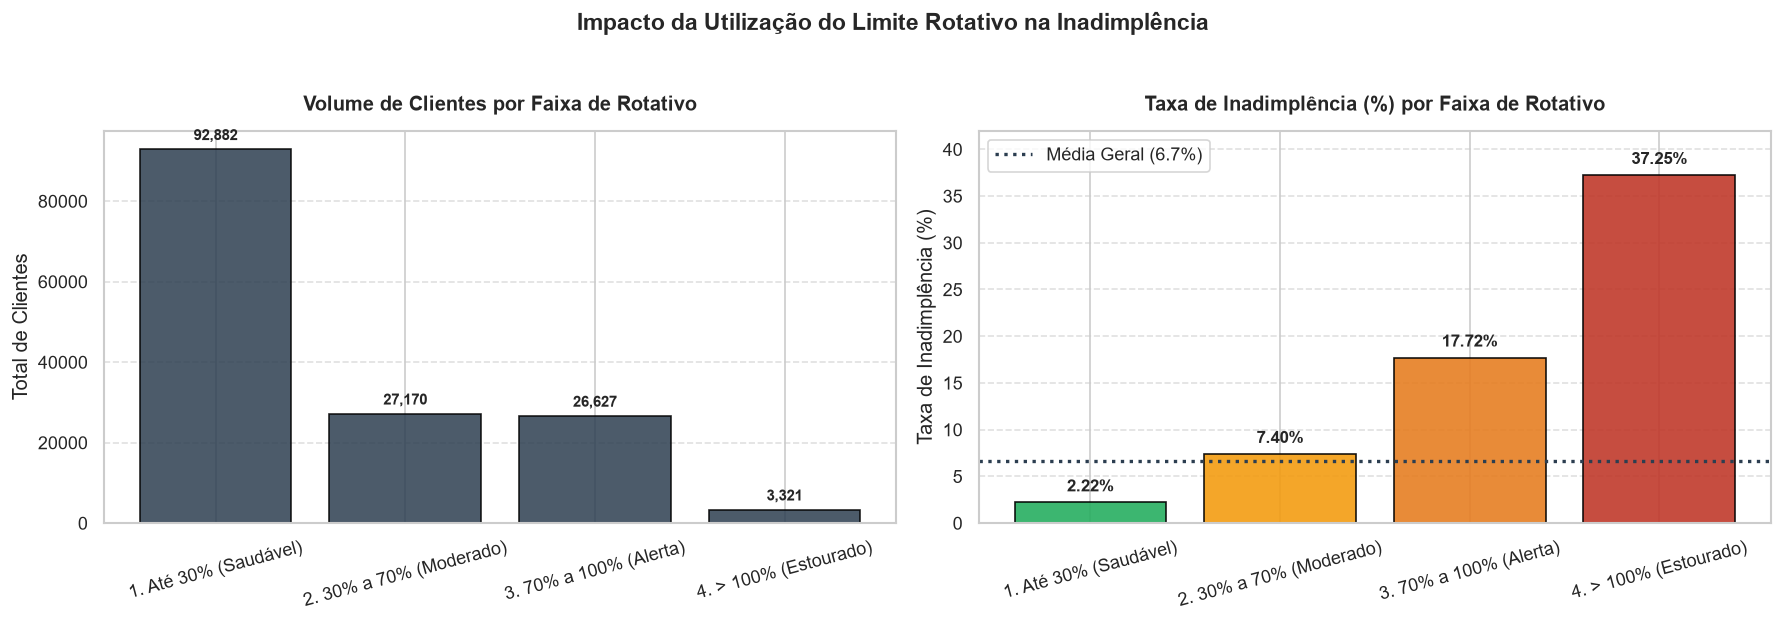

In [16]:
# Categorizando a utilização do crédito rotativo em faixas de risco
def categorizar_rotativo(valor):
    if valor <= 0.30:
        return '1. Até 30% (Saudável)'
    elif valor <= 0.70:
        return '2. 30% a 70% (Moderado)'
    elif valor <= 1.00:
        return '3. 70% a 100% (Alerta)'
    else:
        return '4. > 100% (Estourado)'

df_rot = df.copy()
df_rot['faixa_rotativo'] = df_rot['utilizacao_credito_rotativo'].apply(categorizar_rotativo)

resumo_rot = df_rot.groupby('faixa_rotativo').agg(
    total=('inadimplente_2anos', 'count'),
    inadimplentes=('inadimplente_2anos', 'sum'),
    taxa_inadimplencia=('inadimplente_2anos', lambda x: x.mean() * 100)
).reset_index()

display(resumo_rot)

# Gráficos de volume e taxa de inadimplência por uso do rotativo
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
media_geral = df['inadimplente_2anos'].mean() * 100

bars1 = axes[0].bar(resumo_rot['faixa_rotativo'], resumo_rot['total'], color='#2c3e50', edgecolor='black', alpha=0.85)
axes[0].set_title('Volume de Clientes por Faixa de Rotativo', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel('Total de Clientes')
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars1:
    h = bar.get_height()
    axes[0].annotate(f'{h:,}', (bar.get_x() + bar.get_width() / 2., h + 1500),
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

cores_rot = ['#27ae60', '#f39c12', '#e67e22', '#c0392b']
bars2 = axes[1].bar(resumo_rot['faixa_rotativo'], resumo_rot['taxa_inadimplencia'], color=cores_rot, edgecolor='black', alpha=0.9)
axes[1].set_title('Taxa de Inadimplência (%) por Faixa de Rotativo', fontsize=12, fontweight='bold', pad=12)
axes[1].set_ylabel('Taxa de Inadimplência (%)')
axes[1].set_ylim(0, 42)
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)
axes[1].axhline(media_geral, color='#2c3e50', linestyle=':', linewidth=2, label=f'Média Geral ({media_geral:.1f}%)')
axes[1].legend(loc='upper left', frameon=True)
for bar in bars2:
    h = bar.get_height()
    axes[1].annotate(f'{h:.2f}%', (bar.get_x() + bar.get_width() / 2., h + 0.8),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Impacto da Utilização do Limite Rotativo na Inadimplência', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### 9. Matriz de Correlação Linear das Variáveis

O mapa de calor abaixo resume a força da relação linear entre todos os pares de variáveis.
- Valores próximos de **+1.0** indicam forte relação positiva (quando uma sobe, a outra também sobe).
- O triângulo superior foi ocultado para evitar duplicação de informações.

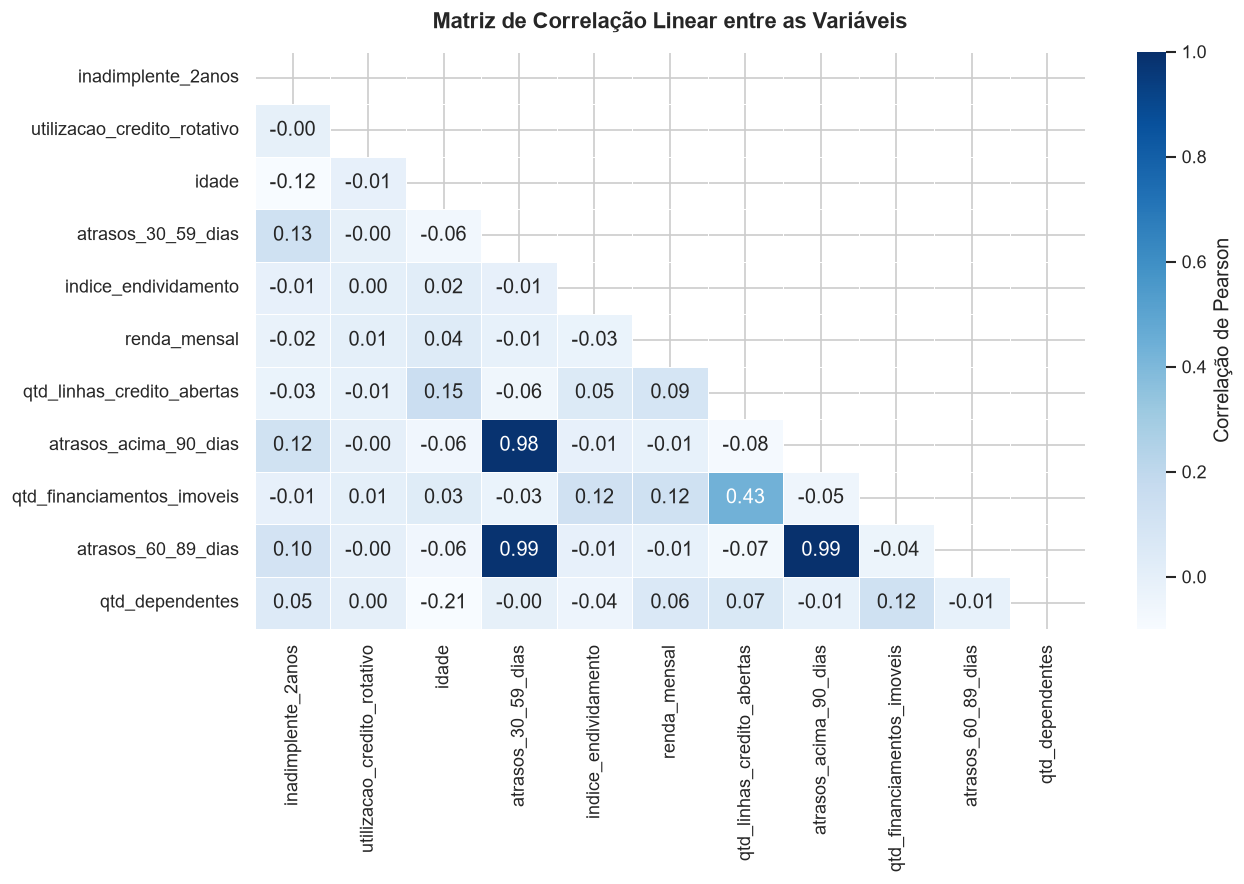

In [17]:
# Matriz de correlação com máscara triangular superior
plt.figure(figsize=(11, 7.5))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=-0.1, vmax=1.0,
            mask=mask, linewidths=0.5, cbar_kws={'label': 'Correlação de Pearson'})
plt.title('Matriz de Correlação Linear entre as Variáveis', fontsize=13, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

### 10. Preparação dos Dados para Modelagem (Machine Learning)

Para que os algoritmos de machine learning possam ser treinados e avaliados com rigor metodológico:
1. **Imputação de Valores Ausentes:** Preenchemos os dados faltantes de `renda_mensal` e `qtd_dependentes` pela **mediana** (com `SimpleImputer`), que é imune a distorções causadas por outliers extremos.
2. **Divisão Treino e Teste:** Separamos **70% para treino** (105.000 clientes) e **30% para teste** (45.000 clientes não vistos).
3. **Estratificação (`stratify=y`):** Como apenas 6,68% dos clientes são inadimplentes, a estratificação garante que essa exata proporção de 6,68% seja rigorosamente mantida tanto no treino quanto no teste.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Separando features (X) e variável alvo (y)
X = df.drop(columns=['inadimplente_2anos'])
y = df['inadimplente_2anos']

# 1. Imputação de valores nulos pela mediana
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# 2. Divisão estratificada (70% treino / 30% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.3, random_state=42, stratify=y
)

print(f"X_train (Treino): {X_train.shape[0]:,} linhas e {X_train.shape[1]} colunas")
print(f"X_test (Teste):   {X_test.shape[0]:,} linhas e {X_test.shape[1]} colunas")
print(f"Taxa de inadimplentes no Treino: {y_train.mean()*100:.2f}%")
print(f"Taxa de inadimplentes no Teste:  {y_test.mean()*100:.2f}%")

Dimensões dos Dados:
X_train (Treino): 105,000 linhas e 10 colunas
X_test (Teste):   45,000 linhas e 10 colunas
Taxa de inadimplentes no Treino: 6.68%
Taxa de inadimplentes no Teste:  6.68%


### 11. Treinamento e Comparação de Modelos (AUC-ROC)

Comparamos 3 algoritmos amplamente utilizados no mercado de risco de crédito:
1. **Regressão Logística (com Normalização StandardScaler):** O padrão bancário regulatório tradicional.
2. **Árvore de Decisão (`DecisionTreeClassifier`, max_depth=4):** Um modelo baseado em regras lógicas, altamente interpretável.
3. **Random Forest (`RandomForestClassifier`, 100 árvores):** Um ensemble que combina 100 árvores diferentes para máxima precisão e estabilidade.

> **Por que avaliamos com AUC-ROC em vez de Acurácia?**
> Como 93,3% da base é adimplente, um modelo ingênuo que chutasse "ninguém atrasa" teria 93,3% de acurácia, mas seria inútil para o banco. A métrica **AUC-ROC** mede a capacidade real do modelo de ordenar clientes do maior para o menor risco (0.50 = chute aleatório; 1.00 = modelo perfeito).

Resultados de Performance (AUC-ROC no conjunto de teste de 45.000 clientes):
1. Regressão Logística: AUC = 0.7070 (70.7%)
2. Árvore de Decisão:   AUC = 0.8287 (82.9%)
3. Random Forest:       AUC = 0.8635 (86.4%)


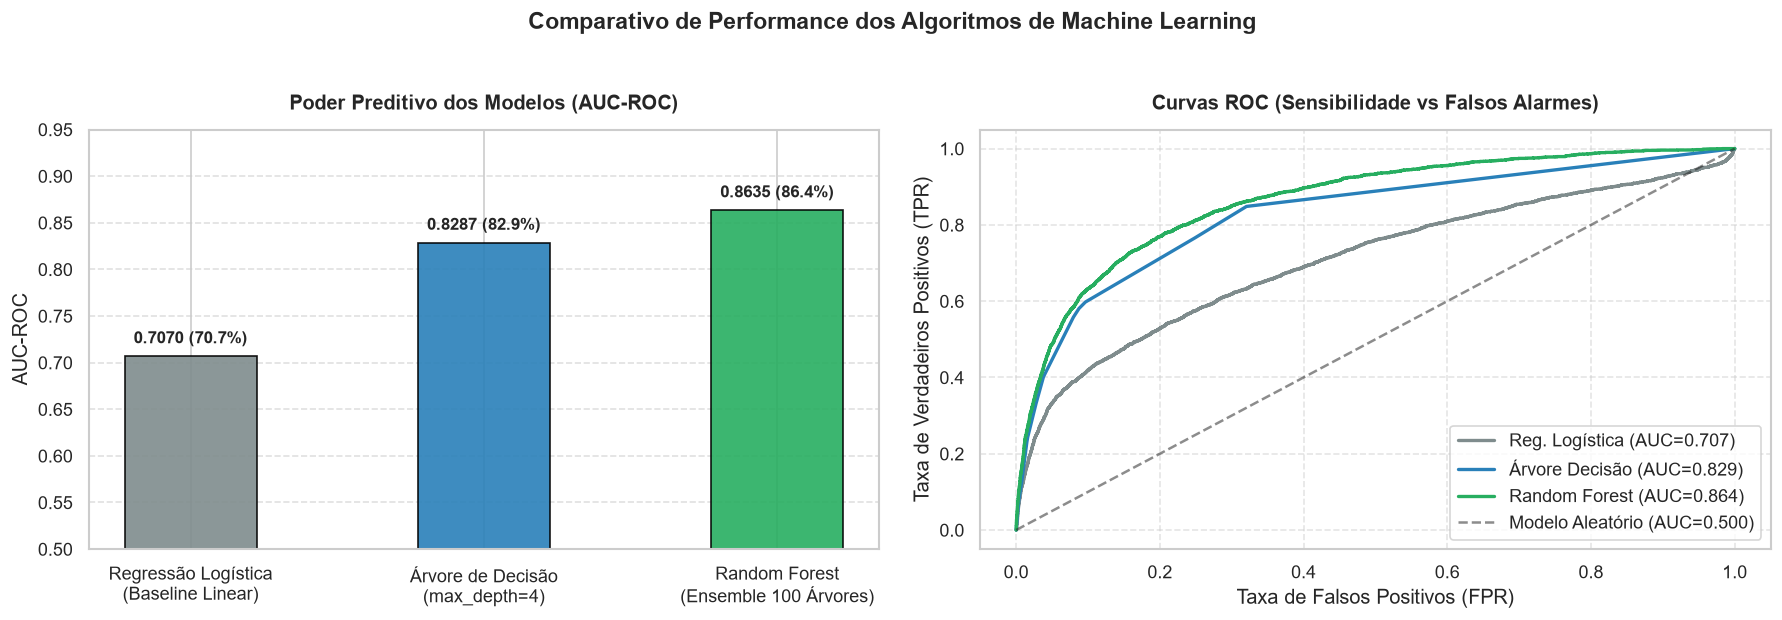

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

# 1. Regressão Logística com Normalização
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42))
])
pipe_lr.fit(X_train, y_train)
y_prob_lr = pipe_lr.predict_proba(X_test)[:, 1]
auc_lr = roc_auc_score(y_test, y_prob_lr)

# 2. Árvore de Decisão (profundidade controlada para interpretabilidade)
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
y_prob_dt = dt.predict_proba(X_test)[:, 1]
auc_dt = roc_auc_score(y_test, y_prob_dt)

# 3. Random Forest (100 árvores)
rf = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_prob_rf = rf.predict_proba(X_test)[:, 1]
auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"1. Regressão Logística: AUC = {auc_lr:.4f} ({auc_lr*100:.1f}%)")
print(f"2. Árvore de Decisão:   AUC = {auc_dt:.4f} ({auc_dt*100:.1f}%)")
print(f"3. Random Forest:       AUC = {auc_rf:.4f} ({auc_rf*100:.1f}%)")

# Gráfico comparativo de performance
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
modelos = ['Regressão Logística\n(Baseline Linear)', 'Árvore de Decisão\n(max_depth=4)', 'Random Forest\n(Ensemble 100 Árvores)']
aucs = [auc_lr, auc_dt, auc_rf]
cores_auc = ['#7f8c8d', '#2980b9', '#27ae60']

bars_auc = axes[0].bar(modelos, aucs, color=cores_auc, width=0.45, edgecolor='black', alpha=0.9)
axes[0].set_title('Poder Preditivo dos Modelos (AUC-ROC)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel('AUC-ROC')
axes[0].set_ylim(0.5, 0.95)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars_auc:
    h = bar.get_height()
    axes[0].annotate(f'{h:.4f} ({h*100:.1f}%)', (bar.get_x() + bar.get_width() / 2., h + 0.01),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

for prob, label, cor in zip([y_prob_lr, y_prob_dt, y_prob_rf],
                             [f'Reg. Logística (AUC={auc_lr:.3f})',
                              f'Árvore Decisão (AUC={auc_dt:.3f})',
                              f'Random Forest (AUC={auc_rf:.3f})'],
                             cores_auc):
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, label=label, color=cor, linewidth=2)

axes[1].plot([0, 1], [0, 1], 'k--', label='Modelo Aleatório (AUC=0.500)', alpha=0.5)
axes[1].set_title('Curvas ROC (Sensibilidade vs Falsos Alarmes)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (TPR)')
axes[1].legend(loc='lower right', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Comparativo de Performance dos Algoritmos de Machine Learning', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### 12. Visualização da Árvore de Decisão (O Fluxograma de Risco)

Diferente de modelos "caixa preta", a Árvore de Decisão permite visualizar exatamente o caminho lógico que o modelo percorre para decidir se um cliente é de alto ou baixo risco.
- **Nó Raiz:** O primeiro critério mais decisivo do modelo.
- Se a condição for verdadeira, segue para a esquerda; se falsa, segue para a direita.
- Quanto mais azul o nó, maior a certeza de adimplência (bom pagador); quanto mais laranja, maior o risco de calote.

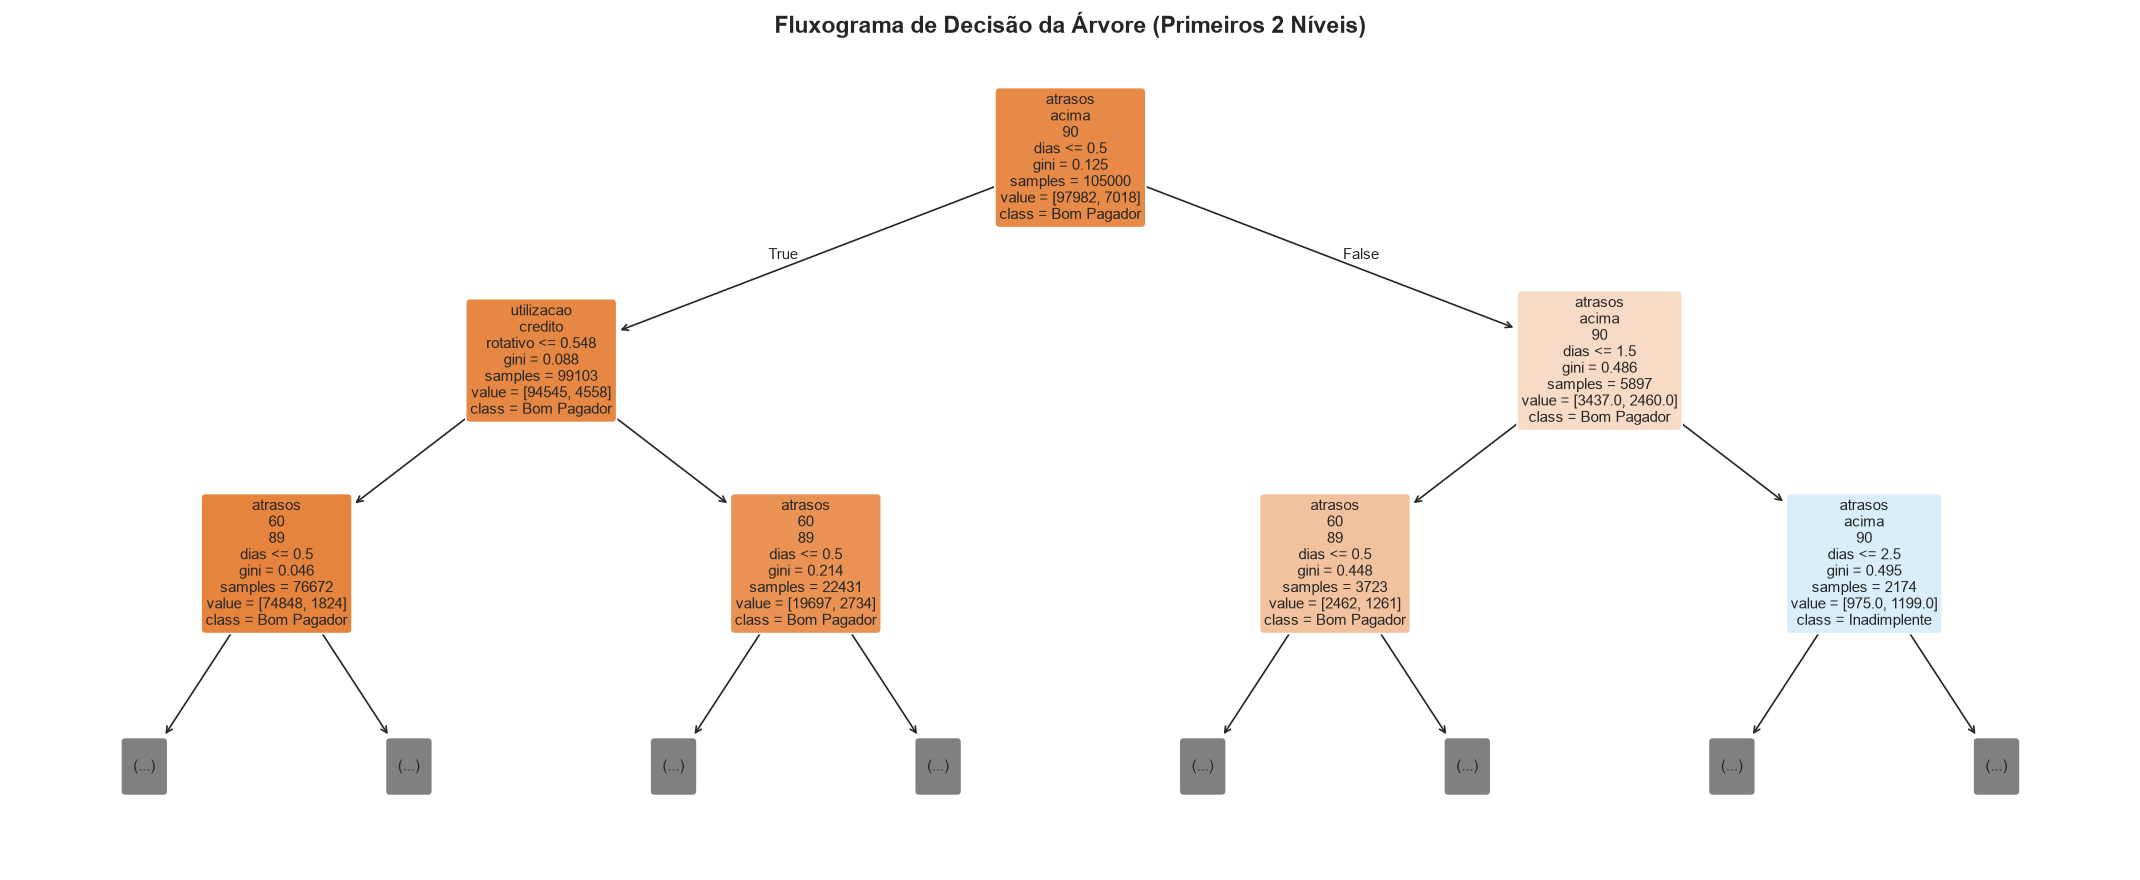

In [20]:
from sklearn.tree import plot_tree

# Visualização dos 2 primeiros níveis da árvore para máxima legibilidade
plt.figure(figsize=(18, 7.5))
nomes_quebrados = [c.replace('_', '\n') for c in X.columns]

plot_tree(
    dt,
    feature_names=nomes_quebrados,
    class_names=['Bom Pagador', 'Inadimplente'],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=2
)
plt.title('Fluxograma de Decisão da Árvore (Primeiros 2 Níveis)', fontsize=14, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

### 13. Ranking de Importância das Variáveis (Feature Importance)

O algoritmo Random Forest avalia o impacto de cada variável ao longo de 100 árvores de decisão e atribui um percentual relativo de importância (Índice de Gini).
- Isso responde com precisão científica à pergunta de negócio: **"O que mais causa inadimplência?"**.

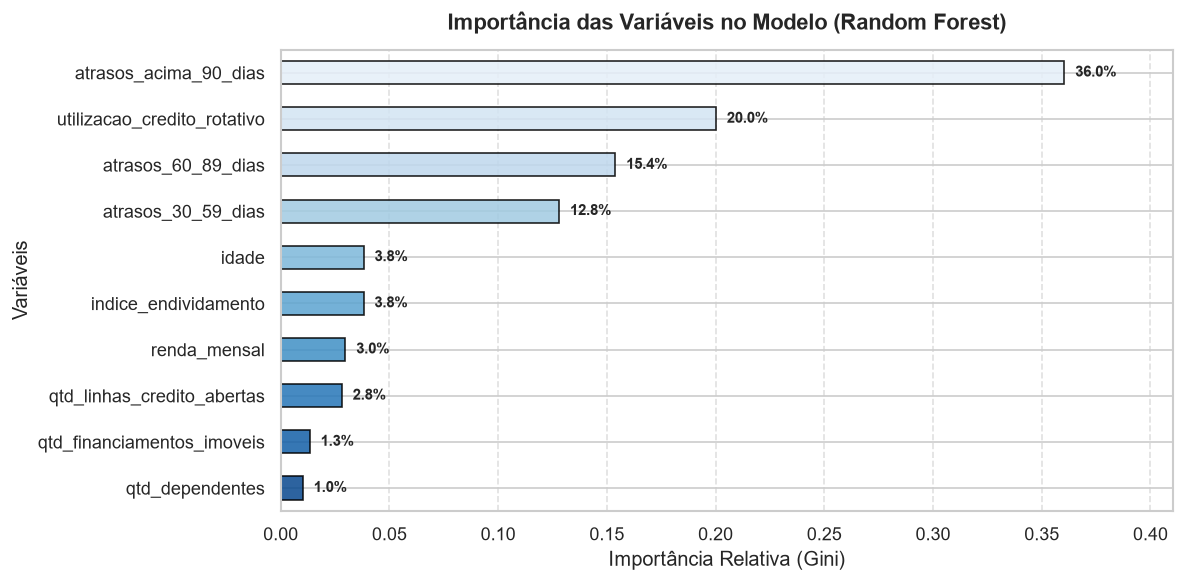

In [21]:
# Ranking de importância das variáveis segundo o Random Forest
importancias = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
cores_imp = sns.color_palette('Blues_r', len(importancias))
importancias.plot(kind='barh', color=cores_imp, edgecolor='black', alpha=0.85)
plt.title('Importância das Variáveis no Modelo (Random Forest)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Importância Relativa (Gini)')
plt.ylabel('Variáveis')
plt.grid(axis='x', linestyle='--', alpha=0.6)

for i, v in enumerate(importancias):
    plt.text(v + 0.005, i, f'{v*100:.1f}%', va='center', fontweight='bold', fontsize=9)

plt.xlim(0, max(importancias) + 0.05)
plt.tight_layout()
plt.show()

### 14. Conclusões e Síntese Executiva do Projeto

1. **As variáveis rainhas do risco:**
   - A **utilização do limite rotativo** (`utilizacao_credito_rotativo`) e o histórico de **atrasos graves de 90+ dias** respondem por mais de **60% do poder preditivo** de todo o modelo.
   - Clientes com rotativo acima de 100% atingem taxa de calote de **33,5%** (5 vezes a média do banco).

2. **Idade e Dependentes como moduladores de risco:**
   - Clientes **menores de 30 anos** têm risco relativo quase 4 vezes maior do que clientes com **mais de 60 anos** (11,7% vs 3,0%).
   - O número de dependentes amplia o risco de calote de **5,86% (0 filhos)** até **10,38% (4 filhos)**.

3. **Performance dos Modelos:**
   - O **Random Forest** alcançou uma performance de excelência com **AUC-ROC de 86,4%**, superando a Árvore simples (82,9%) e a Regressão Logística linear (70,7%).
   - Isso demonstra que o comportamento do risco de crédito é fortemente **não-linear** e se beneficia de modelos em árvore.

### Próximos Passos (Concluídos e Expansões Futuras):
- [x] Análise exploratória bivariada (idade, dependentes, utilização do rotativo e inadimplência).
- [x] Diagnóstico de esteiras de cobrança (atrasos 30-59, 60-89 e 90+ dias).
- [x] Matriz de correlação linear (heatmap).
- [x] Imputação de dados faltantes via mediana (`renda_mensal` e `qtd_dependentes`).
- [x] Separação treino/teste estratificada (70/30).
- [x] Treinamento e comparativo de modelos: Regressão Logística, Árvore de Decisão e Random Forest.
- [x] Visualização do fluxo decisório da Árvore e Ranking de Feature Importance.
- [ ] *Opcional futuro:* Otimização de hiperparâmetros (GridSearchCV / Optuna) e calibração de probabilidade de default (PD).